# Supervised Machine Learning: Classification 
* Attempt to **predict the distinct class** (category) to which a **sample** belongs
    * **Binary classification**&mdash;**two** classes (e.g., “dog” or “cat”)
* [**Digits dataset**](http://scikit-learn.org/stable/datasets/index.html#optical-recognition-of-handwritten-digits-dataset) bundled with scikit-learn
    * 8-by-8 pixel images representing 1797 hand-written digits (0 through 9) 
* Goal: **Predict** which digit an image represents
    * **Multi-classification**&mdash;**10 possible digits** (the classes)
* Train a classification model using **labeled data**—know in advance each digit’s class
* We’ll use one of the simplest machine-learning classification algorithms, **k-nearest neighbors (k-NN)**, to **recognize handwritten digits**

# Part I: Basic model

## 1.1 Loading the Dataset (Step 1)

In [1]:
from sklearn.datasets import load_digits

In [2]:
digits = load_digits()  

### Displaying the Description

In [3]:
print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

    :Number of Instances: 5620
    :Number of Attributes: 64
    :Attribute Information: 8x8 image of integer pixels in the range 0..16.
    :Missing Attribute Values: None
    :Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
    :Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each blo

### Checking the Sample and Target Sizes

In [4]:
digits.target[::100]  # target values of every 100th sample

array([0, 4, 1, 7, 4, 8, 2, 2, 4, 4, 1, 9, 7, 3, 2, 1, 2, 5])

In [5]:
digits.images[13]  # show array for sample image at index 13

array([[ 0.,  2.,  9., 15., 14.,  9.,  3.,  0.],
       [ 0.,  4., 13.,  8.,  9., 16.,  8.,  0.],
       [ 0.,  0.,  0.,  6., 14., 15.,  3.,  0.],
       [ 0.,  0.,  0., 11., 14.,  2.,  0.,  0.],
       [ 0.,  0.,  0.,  2., 15., 11.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  2., 15.,  4.,  0.],
       [ 0.,  1.,  5.,  6., 13., 16.,  6.,  0.],
       [ 0.,  2., 12., 12., 13., 11.,  0.,  0.]])

### Sample Digit Image

In [6]:
import matplotlib.pyplot as plt

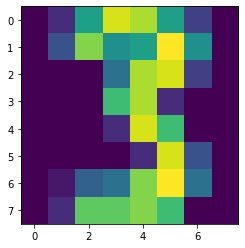

In [7]:
plt.imshow(digits.images[13])

## 1.2 Visualizing the Data (Step 2)
### Creating the Diagram 

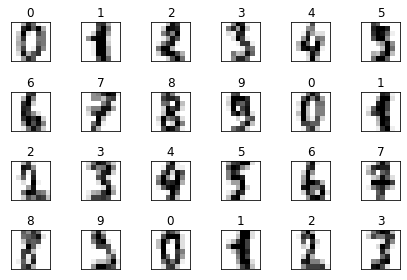

In [8]:
figure, axes = plt.subplots(nrows=4, ncols=6, figsize=(6, 4))

for item in zip(axes.ravel(), digits.images, digits.target):
    axes, image, target = item 
    axes.imshow(image, cmap=plt.cm.gray_r)
    axes.set_xticks([])  # remove x-axis tick marks
    axes.set_yticks([])  # remove y-axis tick marks
    axes.set_title(target)
plt.tight_layout()

## 1.3 Splitting the Data for Training and Testing (Step 3)
* Convention: 
    * **Uppercase `X`** represents **samples**
    * **Lowercase `y`** represents **target values**

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, random_state=11, test_size=0.20)  
# random_state for reproducibility


### Training and Testing Set Sizes

In [10]:
X_train.shape

(1437, 64)

## 1.4 Creating the Model (Step 4)

In [11]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()

## 1.5 Training the Model (Step 5: Training the model)

In [12]:
knn.fit(X=X_train, y=y_train)

KNeighborsClassifier()

## 1.6 Predicting Digit Classes (Step 6: Predicting)
* Returns an array containing the **predicted class of each test image**:

In [13]:
predicted = knn.predict(X=X_test)
expected = y_test

* Predicted digits vs. expected digits for the first 20 test samples

In [14]:
predicted[:20]
expected[:20]

array([0, 4, 9, 9, 3, 1, 4, 1, 5, 0, 4, 9, 4, 1, 5, 3, 3, 8, 3, 6])

In [15]:
predicted[:20]

array([0, 4, 9, 9, 3, 1, 4, 1, 5, 0, 4, 9, 4, 1, 5, 3, 3, 8, 5, 6])

In [16]:
expected[:20]

array([0, 4, 9, 9, 3, 1, 4, 1, 5, 0, 4, 9, 4, 1, 5, 3, 3, 8, 3, 6])

* Locate **all incorrect predictions** for the **entire test set**: 

In [17]:
wrong = [(p, e) for (p, e) in zip(predicted, expected) if p != e]

In [18]:
wrong

[(5, 3), (8, 9), (4, 9), (7, 3), (7, 4)]

### Estimator Method `score`
* Returns an **indication of how well the estimator performs** on **test data** 
* For **classification estimators**, returns the **prediction accuracy** for the test data:

In [19]:
print("Model accuracy:%.2f%%" %(knn.score(X_test,y_test)*100))

Model accuracy:98.61%


# Part II: Accuracy and Optimization 

## 2.1 f-string

**f-string** stands for format strings.This is a new type of string formatting introduced in Python 3.8.1. Earlier versions of python have raw string formatting using “%” operator, format method of string data type.

Formatted string literals are prefixed with 'f' and are similar to the format strings accepted by str.format(). **They contain replacement fields surrounded by curly braces.** The replacement fields are expressions, which are evaluated at run time, and then formatted using the format() protocol.

The f-strings have the f prefix and use {} brackets to evaluate values.

Reference: https://zetcode.com/python/fstring/

In [20]:
courseNum = "CSCI538"
name = "everyone"
f"Hello {name}, welcome to {courseNum}"


'Hello everyone, welcome to CSCI538'

In [21]:
print(f"Hello {name}, welcome to {courseNum}")

Hello everyone, welcome to CSCI538


Format specifiers for types, padding, or aligning are specified after the colon character(:); for instance: f'{score:.3}', where score is a variable name.

#### Format floats

In [22]:
score =92.65

print(f"The score is {score:4.2f}")

The score is 92.65


#### Format percentage

In [23]:
accuracy =0.8

print(f"The accuract is {accuracy:.2%}")

The accuract is 80.00%


#### Basic math 
Python 3.8 introduced the self-documenting expression with the = character.

In [24]:
import math
x=0.8
#print(f"{math.sin(x) = }") # due to the version, you may have syntax error 
#print(f"{math.cos(x) = }")

<hr style="height:2px; border:none; color:black; background-color:black;">

## 2.2 Metrics for Measuring Model Accuracy 

### 2.2.1 Estimator Method `score`
* Returns an **indication of how well the estimator performs** on **test data** 
* For **classification estimators**, returns the **prediction accuracy** for the test data:

In [25]:
print(f'{knn.score(X_test, y_test):.2%}')

98.61%


* `kNeighborsClassifier` with default **_k_** of 5 achieved **98.61% prediction accuracy** using only the estimator’s **default parameters**
* Can use **hyperparameter tuning** to try to determine the **optimal value for _k_**

<hr style="height:2px; border:none; color:black; background-color:black;">

### 2.2.2 Confusion Matrix (1 of 2)
* Shows correct and incorrect predicted values (the **hits** and **misses**) for a given class 

In [26]:
from sklearn.metrics import confusion_matrix

In [27]:
confusion = confusion_matrix(y_true=expected, y_pred=predicted)

In [28]:
confusion

array([[38,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 37,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0, 39,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 39,  0,  1,  0,  1,  0,  0],
       [ 0,  0,  0,  0, 40,  0,  0,  1,  0,  0],
       [ 0,  0,  0,  0,  0, 27,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0, 30,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 36,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0, 34,  0],
       [ 0,  0,  0,  0,  1,  0,  0,  0,  1, 35]], dtype=int64)

#### Confusion Matrix (2 of 2)
* **Correct predictions** shown on **principal diagonal** from top-left to bottom-right
* **Nonzero values** not on **principal diagonal** indicate **incorrect predictions** 
* Each **row** represents **one distinct class** (0–9) 
* **Columns** specify how many **test samples** were classified into classes 0–9 
* **Row 0** shows digit class **`0`**&mdash;**all 0s were predicted correctly**
>`[38,  0,  0,  0,  0,  0,  0,  0,  0,  0]`
* **Row 9** shows digit class **`9`**&mdash;**two 9s were predicted incorrectly**
>`[ 0,  0,  0,  0,  1,  0,  0,  0,  1, 35]`

    * **Correctly predicted 94.59%** (35 of 37) of `9`s
    * 2s harder to recognize

### 2.2.3 Visualizing the Confusion Matrix 
* A **heat map** displays **values** as **colors**
* Convert the **confusion matrix** into a **`DataFrame`**, then graph it
    * **`DataFrame`** is a 2-dimensional labeled data structure with columns of potentially different types. You can think of it like a spreadsheet or SQL table, or a dict of Series objects. It is generally the most commonly used pandas object.
* **Principal diagonal** and **incorrect predictions** stand out nicely in **heat map**

#### Pandas is the most commonly used library for data analysis in python

In [29]:
import pandas as pd

In [30]:
confusion_df = pd.DataFrame(confusion, index=range(10), columns=range(10))

#### Seaborn is a data visualization library built on top of matplotlib and closely integrated with pandas.
* figsize(float, float), default: rcParams["figure.figsize"] (default: [6.4, 4.8])
  Width, height in inches.

In [31]:
import seaborn as sns

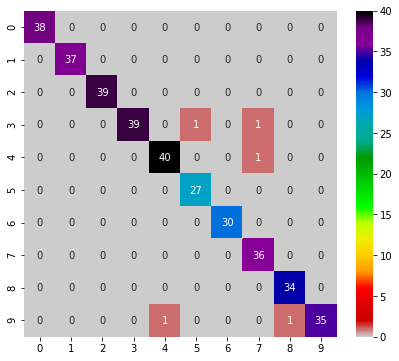

In [32]:
figure = plt.figure(figsize=(7, 6))
axes = sns.heatmap(confusion_df, annot=True, 
                   cmap=plt.cm.nipy_spectral_r) 

### 2.2.4 Classification Report
Reference: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html

**`sklearn.metrics.classification_report(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=False, zero_division='warn')`** 

from sklearn.metrics import classification_report

y_true = [0, 1, 2, 2, 2]

y_pred = [0, 0, 2, 2, 1]

target_names = ['class 0', 'class 1', 'class 2']

print(classification_report(y_true, y_pred, target_names=target_names))

              precision    recall  f1-score   support

     class 0       0.50      1.00      0.67         1
     class 1       0.00      0.00      0.00         1
     class 2       1.00      0.67      0.80         3

    accuracy                           0.60         5
   macro avg       0.50      0.56      0.49         5
weighted avg       0.70      0.60      0.61         5

y_pred = [1, 1, 0]

y_true = [1, 1, 1]

print(classification_report(y_true, y_pred, labels=[1, 2, 3]))

              precision    recall  f1-score   support

           1       1.00      0.67      0.80         3
           2       0.00      0.00      0.00         0
           3       0.00      0.00      0.00         0

   micro avg       1.00      0.67      0.80         3
   macro avg       0.33      0.22      0.27         3
weighted avg       1.00      0.67      0.80         3

In [33]:
from sklearn.metrics import classification_report

In [34]:
names = [str(digit) for digit in digits.target_names]

In [35]:
names

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

In [36]:
print(classification_report(expected, predicted, 
       target_names=names))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        38
           1       1.00      1.00      1.00        37
           2       1.00      1.00      1.00        39
           3       1.00      0.95      0.97        41
           4       0.98      0.98      0.98        41
           5       0.96      1.00      0.98        27
           6       1.00      1.00      1.00        30
           7       0.95      1.00      0.97        36
           8       0.97      1.00      0.99        34
           9       1.00      0.95      0.97        37

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



## 2.2.5 K-Fold Cross-Validation


When creating a model, a key goal is to **`ensure that it is capable of making accurate predictions`**
for data it has not yet seen. Two common problems that prevent accurate predications are overfitting and overfitting.

<img src="https://3gp10c1vpy442j63me73gy3s-wpengine.netdna-ssl.com/wp-content/uploads/2018/03/Screen-Shot-2018-03-22-at-11.22.15-AM-e1526498075543.png" width=489 height=149 />

#### In Statistics, 
* **Overfitting** is "the production of an analysis that corresponds too closely or exactly to a particular set of data, and may therefore fail to fit additional data or predict future observations reliably". 
* **Underfitting**, the counterpart of overfitting, happens when a machine learning model is not complex enough to accurately capture relationships between a dataset’s features and a target variable.

For additional information on underfitting and overfitting, see
* https://en.wikipedia.org/wiki/Overfitting
* https://machinelearningmastery.com/overfitting-and-underfittingwith-machine-learning-algorithms/

### K-Fold Cross-Validation is a common technique to reduce overfitting

* Uses **all of your data** for **training and testing** to get a better sense of how well your model will make predictions for new data repeatedly training and testing the model with different portions of the dataset.
* **Splits the dataset** into **_k_ equal-size folds** (unrelated to**&nbsp;k** in the k-nearest neighbors algorithm)
* **Repeatedly trains** your model with **_k_ – 1 folds** and **test the model** with the **remaining fold**
* Consider using **_k_ = 10** with **folds numbered 1 through 10**
	* **train** with **folds 1–9**, then **test** with **fold 10**
	* **train** with **folds 1–8 and 10**, then **test** with **fold 9**
	* **train** with **folds 1–7** and **9–10**, then **test** with **fold 8**
    * ...
    <img src="https://miro.medium.com/max/3738/1*kheTr2G_BIB6S4UnUhFp8g.png" width=489 height=149 />
    

### `KFold` Class
* **`KFold`** class and function **`cross_val_score`** perform **k-fold cross validation** 
* **`n_splits=10`** specifies the **number of folds**
* **`shuffle=True`** **randomizes** the data before **splitting it into folds** 
	* Particularly **important** if the **samples** might be **ordered** or **grouped** (as in **Iris dataset** we'll see later)

In [37]:
from sklearn.model_selection import KFold

In [38]:
kfold = KFold(n_splits=10, random_state=11, shuffle=True)

<hr style="height:2px; border:none; color:black; background-color:black;">

### Calling Function `cross_val_score` to Train and Test Your Model (1 of 2)
* **`estimator=knn`** &mdash; **estimator** to validate
* **`X=digits.data`** &mdash; **samples** to use for training and testing
* **`y=digits.target`** &mdash; **target predictions** for the samples
* **`cv=kfold`** &mdash; **cross-validation generator** that defines how to **split** the **samples** and **targets** for training and testing



In [39]:
from sklearn.model_selection import cross_val_score

In [40]:
scores = cross_val_score(estimator=knn, X=digits.data, y=digits.target, cv=kfold)

### Calling Function `cross_val_score` to Train and Test Your Model (2 of 2)
* Lowest accuracy was **97.78%** &mdash; one was **100%**

In [41]:
scores

array([0.97777778, 0.99444444, 0.98888889, 0.97777778, 0.98888889,
       0.99444444, 0.97777778, 0.98882682, 1.        , 0.98324022])

In [42]:
print(f'Mean accuracy: {scores.mean():.2%}')
print("Model accuracy:%.2f%%" %(knn.score(X_test,y_test)*100))

Mean accuracy: 98.72%
Model accuracy:98.61%


* Mean accuracy even better than the **97.618% we achieved** when we **trained** the model with **75%** of the data and **tested** the model with **25%** earlier

### 2.2.6 Hyperparameter Tuning


In [43]:
for k in range(1, 20, 2):
     kfold = KFold(n_splits=10, random_state=11, shuffle=True)
     knn = KNeighborsClassifier(n_neighbors=k)
     scores = cross_val_score(estimator=knn, 
         X=digits.data, y=digits.target, cv=kfold)
     print(f'k={k:<2}; mean accuracy={scores.mean():.2%}; ' +
           f'standard deviation={scores.std():.2%}')

k=1 ; mean accuracy=98.83%; standard deviation=0.58%
k=3 ; mean accuracy=98.78%; standard deviation=0.78%
k=5 ; mean accuracy=98.72%; standard deviation=0.75%
k=7 ; mean accuracy=98.44%; standard deviation=0.96%
k=9 ; mean accuracy=98.39%; standard deviation=0.80%
k=11; mean accuracy=98.39%; standard deviation=0.80%
k=13; mean accuracy=97.89%; standard deviation=0.89%
k=15; mean accuracy=97.89%; standard deviation=1.02%
k=17; mean accuracy=97.50%; standard deviation=1.00%
k=19; mean accuracy=97.66%; standard deviation=0.96%


### 2.2.7 Running Multiple Models to Find the Best One
* **Difficult to know in advance** which machine learning model(s) will **perform best for a given dataset**
    * Especially when they hide the details of how they operate
* Even though the **`KNeighborsClassifier`** predicts digit images with a high degree of accuracy, it’s **possible** that other estimators are **even more accurate**
* Let’s **compare** **`KNeighborsClassifier`**, **`SVC`** and **`GaussianNB`**
    * Support Vector Classifer (SVC)
         * finds the linear hyperplane that separate classes with the maxium Margin
         * <img src="https://miro.medium.com/max/1000/1*z_B0o4JbD0C6gpmcenUc4w.jpeg" width=489 height=149 />
    * GaussianNB
        * In this classifier, the assumption is that data from each label is drawn from a simple Gaussian distribution.
        * <img src="https://jakevdp.github.io/PythonDataScienceHandbook/figures/05.05-gaussian-NB.png" width=489 height=149 />

In [44]:
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

In [45]:
estimators = {
     'KNeighborsClassifier': knn, 
     'SVC': SVC(gamma='scale'),
     'GaussianNB': GaussianNB()}

In [46]:
for estimator_name, estimator_object in estimators.items():
     kfold = KFold(n_splits=10, random_state=11, shuffle=True)
     scores = cross_val_score(estimator=estimator_object, 
         X=digits.data, y=digits.target, cv=kfold)
     print(f'{estimator_name:>20}: ' + 
           f'mean accuracy={scores.mean():.2%}; ' +
           f'standard deviation={scores.std():.2%}')

KNeighborsClassifier: mean accuracy=97.66%; standard deviation=0.96%
                 SVC: mean accuracy=98.72%; standard deviation=0.79%
          GaussianNB: mean accuracy=84.48%; standard deviation=3.47%
